## Cars' Price Predictor using **XGBoosting**

### Libs importing

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
import optuna
import pickle
import os
import matplotlib.pyplot as plt
import seaborn as sns

/home/abod/Documents/Projects/UNI/DE_Used_Autos/tst/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv('../Daten/autoscout24-germany-dataset.csv')
print(f"Original dataset shape: {df.shape}")

Original dataset shape: (46405, 9)


### Clean the Data

In [ ]:
df_clean = df.dropna()
df_clean = df_clean[
    (df_clean['price'] > 500) & (df_clean['price'] < 100000) &
    (df_clean['mileage'] >= 0) & (df_clean['mileage'] < 500000) &
    (df_clean['hp'] > 0) & (df_clean['hp'] < 1000) &
    (df_clean['year'] >= 1990) & (df_clean['year'] <= 2023)
]


# Remove price outliers
Q1, Q3 = df_clean['price'].quantile([0.25, 0.75])
IQR = Q3 - Q1
df_clean = df_clean[(df_clean['price'] >= Q1 - 1.5*IQR) & (df_clean['price'] <= Q3 + 1.5*IQR)]
print(f"Cleaned dataset shape: {df_clean.shape}")

Cleaned dataset shape: (42530, 9)


### Feature Engineering (add a new feature)

In [5]:
df_features = df_clean.copy()

current_year = 2023
df_features['age'] = current_year - df_features['year']
df_features['mileage_per_year'] = df_features['mileage'] / (df_features['age'] + 1)
df_features['hp_per_year'] = df_features['hp'] / (df_features['age'] + 1)
df_features['log_mileage'] = np.log1p(df_features['mileage'])

df_features['age_category'] = pd.cut(df_features['age'], 
                                   bins=[0, 3, 7, 12, float('inf')],
                                   labels=['New', 'Recent', 'Mature', 'Old'])
df_features['mileage_category'] = pd.cut(df_features['mileage'], 
                                       bins=[0, 50000, 100000, 150000, 200000, float('inf')],
                                       labels=['VeryLow', 'Low', 'Medium', 'High', 'VeryHigh'])

### Encode categorical variables and split them into test and train data

In [6]:
label_encoders = {}
categorical_cols = ['make', 'model', 'fuel', 'gear', 'offerType', 'age_category', 'mileage_category']

df_model = df_features.copy()
for col in categorical_cols:
    le = LabelEncoder()
    df_model[col + '_encoded'] = le.fit_transform(df_model[col].astype(str))
    label_encoders[col] = le

# Select features
feature_columns = [
    'mileage', 'hp', 'year', 'age', 'mileage_per_year', 'hp_per_year', 'log_mileage',
    'make_encoded', 'model_encoded', 'fuel_encoded', 'gear_encoded', 'offerType_encoded',
    'age_category_encoded', 'mileage_category_encoded'
]

X = df_model[feature_columns]
y = df_model['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=37)

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

Training set: (34024, 14), Test set: (8506, 14)


### Train the first version of the Model

In [7]:
erst_model = xgb.XGBRegressor(n_estimators=100, max_depth=6, random_state=37)
erst_model.fit(X_train, y_train)
y_pred_first = erst_model.predict(X_test)

erst_r2 = r2_score(y_test, y_pred_first)
erst_rmse = np.sqrt(mean_squared_error(y_test, y_pred_first))
print(f"First Model - R²: {erst_r2:.4f}, RMSE: {erst_rmse:.0f}")

First Model - R²: 0.9460, RMSE: 1784


### Function to Optimize The Model  with Optuna (Bayesian Optimization)

In [8]:
def optimizer(trial):
    params = {
        'n_estimators': trial.suggest_categorical('n_estimators', [200, 300, 400]),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 1),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.5, 2),
        'random_state': 37,
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**params)
    score = -cross_val_score(model, X_train, y_train, cv=3, scoring='neg_mean_squared_error', n_jobs=-1).mean()
    return score

### Get best parameters and re-train the model (with best options)

In [12]:
study = optuna.create_study(direction='minimize')
study.optimize(optimizer, n_trials=40)

# Get best parameters
best_params = study.best_params
best_value = study.best_value

print(f"Best parameters: {best_params}")
print(f"Best RMSE: {np.sqrt(best_value):.2f}")

best_model = xgb.XGBRegressor(**best_params, random_state=37, n_jobs=-1)
best_model.fit(X_train, y_train)

[I 2025-06-13 00:48:06,847] A new study created in memory with name: no-name-7be215e6-372b-4bc6-ba59-293bf0858601
[I 2025-06-13 00:48:08,281] Trial 0 finished with value: 3763980.0 and parameters: {'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.01955538645155606, 'subsample': 0.8126740684554231, 'colsample_bytree': 0.7192863345749918, 'reg_alpha': 0.15138345817253374, 'reg_lambda': 1.051788203327517}. Best is trial 0 with value: 3763980.0.
[I 2025-06-13 00:48:09,424] Trial 1 finished with value: 3216057.4166666665 and parameters: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.12080629417816835, 'subsample': 0.8210657584891037, 'colsample_bytree': 0.9907157379048701, 'reg_alpha': 0.731899375048255, 'reg_lambda': 1.8695424561599345}. Best is trial 1 with value: 3216057.4166666665.
[I 2025-06-13 00:48:10,394] Trial 2 finished with value: 3435207.6666666665 and parameters: {'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.05855157559577839, 'subsample': 0.72358100

Best parameters: {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.14376584792113684, 'subsample': 0.9555924681524486, 'colsample_bytree': 0.8624860907430514, 'reg_alpha': 0.23111338675674764, 'reg_lambda': 1.4201586993036381}
Best RMSE: 1654.00


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8624860907430514
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [13]:
y_pred_optimized = best_model.predict(X_test)

optimized_r2 = r2_score(y_test, y_pred_optimized)
optimized_rmse = np.sqrt(mean_squared_error(y_test, y_pred_optimized))
optimized_mae = mean_absolute_error(y_test, y_pred_optimized)
mape = np.mean(np.abs((y_test - y_pred_optimized) / y_test)) * 100

print(f"\nFinal Model Performance:")
print(f"R² Score: {optimized_r2:.4f}")
print(f"RMSE: {optimized_rmse:.0f} €")
print(f"MAE: {optimized_mae:.0f} €")
print(f"MAPE: {mape:.1f}%")

print(f"\nImprovement: R² +{optimized_r2 - erst_r2:.4f}, RMSE -{erst_rmse - optimized_rmse:.0f}")



Final Model Performance:
R² Score: 0.9530
RMSE: 1654 €
MAE: 1177 €
MAPE: 10.3%

Improvement: R² +0.0070, RMSE -130


### Plot the data with model predictions

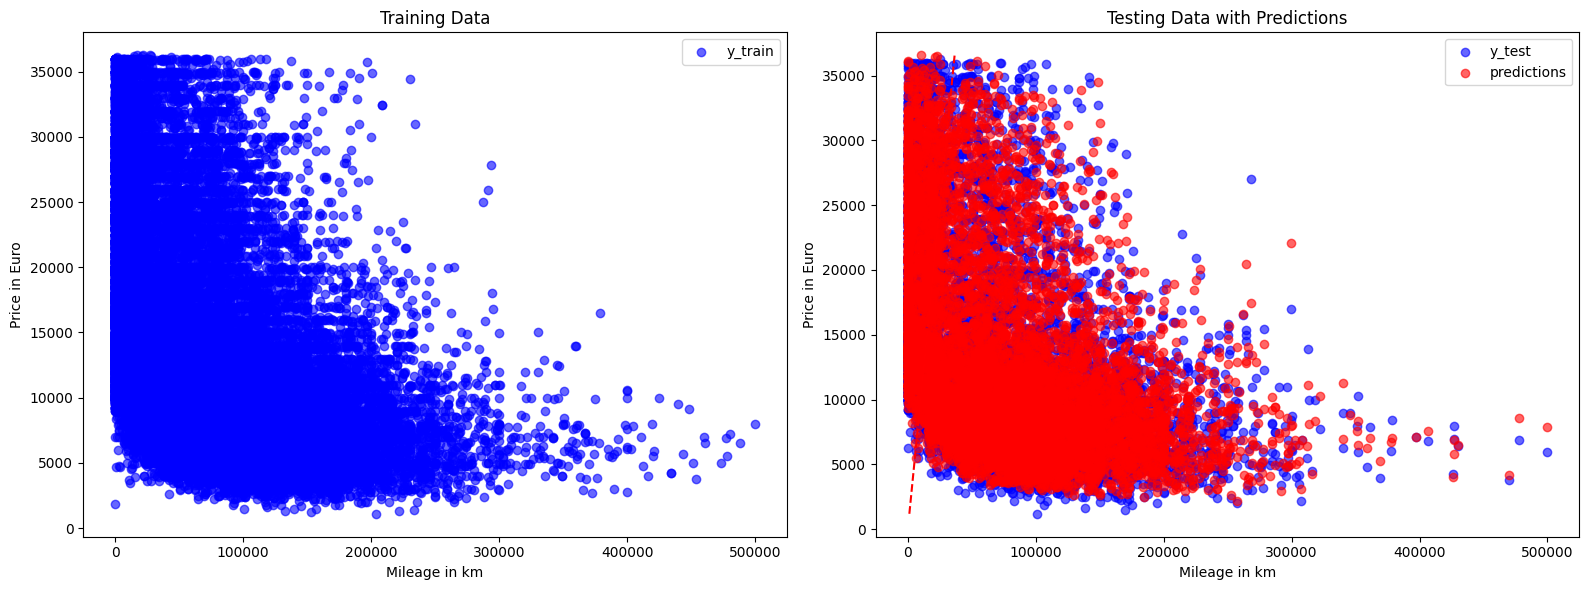

In [15]:
def plot_results(X_train, y_train, X_test, y_test, predictions):

    train_feature = X_train['mileage']
    test_feature = X_test['mileage']

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Plot Training Data
    axes[0].scatter(train_feature, y_train, color='blue', alpha=0.6, label='y_train')
    axes[0].set_title("Training Data")
    axes[0].set_xlabel("Mileage in km")
    axes[0].set_ylabel("Price in Euro")
    axes[0].legend()
    
    # Plot Testing Data with Predictions
    axes[1].scatter(test_feature, y_test, color='blue', alpha=0.6, label='y_test')
    axes[1].scatter(test_feature, predictions, color='red', alpha=0.6, label='predictions')
    axes[1].set_title("Testing Data with Predictions")
    axes[1].set_xlabel("Mileage in km")
    axes[1].set_ylabel("Price in Euro")
    axes[1].legend()
    
    min_val = min(min(y_test), min(predictions))
    max_val = max(max(y_test), max(predictions))
    axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', label='Perfect Prediction')
    
    plt.tight_layout()
    plt.show()
    
plot_results(X_train, y_train, X_test, y_test, y_pred_optimized)

### Is there any relationship between Features and the Price?

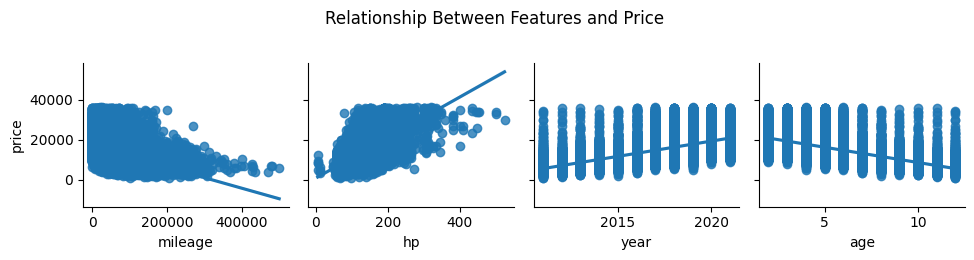

In [19]:
features_to_plot = ['mileage', 'hp', 'year', 'age']
df_plot = df_model[features_to_plot + ['price']].sample(frac=0.3, random_state=37)

sns.pairplot(data=df_plot, y_vars=['price'], x_vars=features_to_plot, height=2.5, kind='reg', diag_kind='hist')
plt.suptitle("Relationship Between Features and Price", y=1.02)
plt.tight_layout()
plt.show()

### How good is my model for predicting the prices over years?

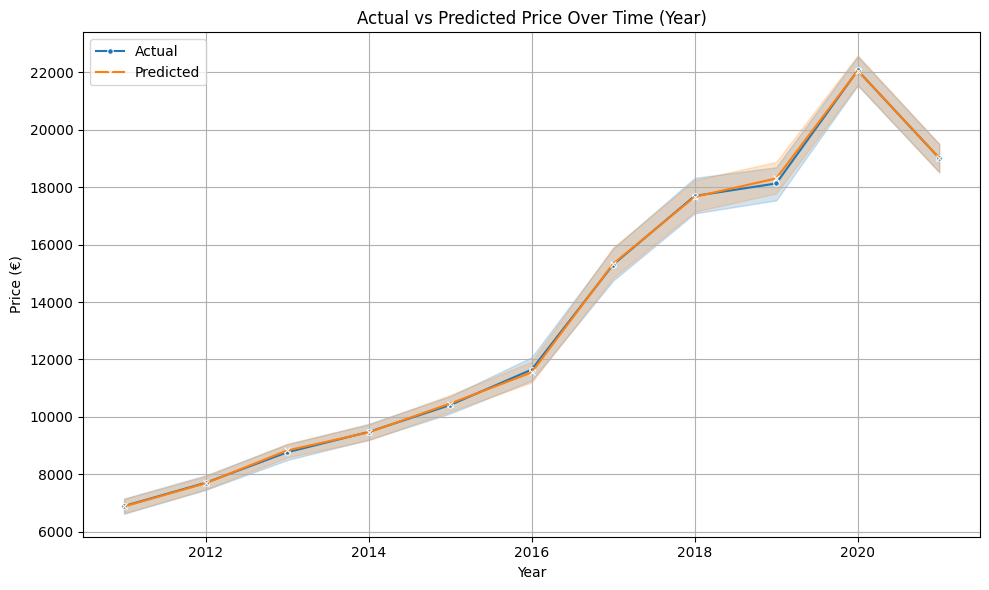

In [ ]:
sorted_idx = X_test['year'].argsort()
X_sorted = X_test.iloc[sorted_idx]
y_sorted = y_test.iloc[sorted_idx]
pred_sorted = y_pred_optimized[sorted_idx]

plt.figure(figsize=(10, 6))
sns.lineplot(x=X_sorted['year'], y=y_sorted, label='Actual', marker='o', markersize=4)
sns.lineplot(x=X_sorted['year'], y=pred_sorted, label='Predicted', marker='x', markersize=4)
plt.title("Actual vs Predicted Price Over Time")
plt.xlabel("Year")
plt.ylabel("Price (€)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Saving the model and encoders (Cause it was better than any model available Online) 😁

In [ ]:
os.makedirs('../models/xgb', exist_ok=True)

# Save model
with open('../models/xgb/xgb_car_price_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

# Save label encoders
with open('../models/xgb/label_encoders.pkl', 'wb') as f:
    pickle.dump(label_encoders, f)

# Save feature columns
with open('../models/xgb/feature_columns.pkl', 'wb') as f:
    pickle.dump(feature_columns, f)

print("Model and encoders saved successfully!")

Model and encoders saved successfully!


### So Last thing 😋 (Price Predictor)

In [ ]:
# -*- I already saved the model with its encoders and feature columns -*-
# -*- So we will simply load them for prediction, without any preprocessing or training -*-
# -*- if you need to re-train the model, you can comment or remove the loading section -*-
#                -*- and run the code from the beginning above -*-


# Load model and encoders for prediction
with open('../models/xgb/xgb_car_price_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

with open('../models/xgb/label_encoders.pkl', 'rb') as f:
    loaded_encoders = pickle.load(f)

with open('../models/xgb/feature_columns.pkl', 'rb') as f:
    loaded_features = pickle.load(f)

# prediction function :)
def predict_car_price(mileage, hp, year, make, model, fuel, gear, offerType):
    age = 2023 - year
    mileage_per_year = mileage / (age + 1)
    hp_per_year = hp / (age + 1)
    log_mileage = np.log1p(mileage)
    
    age_cat = 'New' if age <= 3 else 'Recent' if age <= 7 else 'Mature' if age <= 12 else 'Old'
    mileage_cat = ('VeryLow' if mileage <= 50000 else 'Low' if mileage <= 100000 else 
                   'Medium' if mileage <= 150000 else 'High' if mileage <= 200000 else 'VeryHigh')

    try:
        make_enc = loaded_encoders['make'].transform([make])[0]
        model_enc = loaded_encoders['model'].transform([model])[0]
        fuel_enc = loaded_encoders['fuel'].transform([fuel])[0]
        gear_enc = loaded_encoders['gear'].transform([gear])[0]
        offer_enc = loaded_encoders['offerType'].transform([offerType])[0]
        age_cat_enc = loaded_encoders['age_category'].transform([age_cat])[0]
        mileage_cat_enc = loaded_encoders['mileage_category'].transform([mileage_cat])[0]
    except KeyError as e:
        print(f"Unknown category: {e}. Using default encoding.")
        make_enc = model_enc = fuel_enc = gear_enc = offer_enc = age_cat_enc = mileage_cat_enc = 0
    
    # Create feature vector
    features = np.array([[mileage, hp, year, age, mileage_per_year, hp_per_year, log_mileage,
                         make_enc, model_enc, fuel_enc, gear_enc, offer_enc,
                         age_cat_enc, mileage_cat_enc]])
    
    return loaded_model.predict(features)[0]

## Let's Do it :>

In [ ]:
first_car = predict_car_price(100000, 150, 2017, 'BMW', '316', 'Diesel', 'Manual', 'Used')

# The same car with different mileage and year
second_car = predict_car_price(10000, 150, 2020, 'BMW', '316', 'Diesel', 'Manual', 'Used')

print(f"\nFirst Car: BMW 316 Diesel (2017, 100k km, 150 HP) → €{first_car:.0f}")
print(f"Second Car: BMW 316 Diesel (2020, 10k km, 150 HP) → €{second_car:.0f}")


First Car: BMW 316 Diesel (2017, 100k km, 150 HP) → €15430
Second Car: BMW 316 Diesel (2020, 10k km, 150 HP) → €27873
